In [1]:
import pandas as pd
import re

In [2]:
df=pd.read_csv("../data/e-ticaret_urun_yorumlari.csv", sep=",",on_bad_lines="skip")
print(df.shape)
print(df.columns)
df.head()

(15170, 2)
Index(['Metin', 'Durum'], dtype='str')


,Metin,Durum
0,evet anlatıldığı gibi,1
1,Daha öncede almıştım bu cihazdan ense ve sakal...,1
2,Ürün gayet başarılı sakal kesmede başlık sayıs...,1
3,Daha öncede aynısını almıştım çok güzel ve kal...,1
4,Erkek kuaförüyüm ense ve sıfır sakal traşı içi...,1


In [3]:
def tr_lower(text):
    return text.replace("I","ı").replace("İ","i").lower()

In [4]:
def clean_text(text):
    text=str(text)
    text=re.sub(r'http\S+|www\.\S+', ' ', text)
    text=tr_lower(text)
    text = re.sub(r'\d+', ' ', text)
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

In [5]:
from zemberek import TurkishMorphology

C:\Desktop\anaconda3\envs\turkce_nlp\Lib\site-packages\zemberek\morphology\turkish_morphology.py:9: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [6]:
morphology=TurkishMorphology.create_with_defaults()

2026-11-14 00:28:01,950 - zemberek.morphology.turkish_morphology - INFO
Msg: TurkishMorphology instance initialized in 6.747663974761963



In [7]:
def lemmatize(text):
    if not text:
        return ""
    words=text.split()
    analyses=morphology.analyze_and_disambiguate(text).best_analysis()
    lemmas=[]

    for w, a in zip(words, analyses):
        lemma=a.item.lemma

        if lemma in ("UNK",""):
            lemma=w
        lemmas.append(lemma)

    return " ".join(lemmas)

In [8]:
stop_words = {
    "ve", "ile", "bir", "bu", "şu", "o", "da", "de", "ki", "mi", "mı",
    "için", "gibi", "ama", "fakat", "ancak", "çok", "daha", "en", "ben",
    "sen", "biz", "siz", "onlar", "ne", "her", "şey", "olarak", "kadar"
}

In [9]:
def remove_stopwords(text):
    return " ".join(w for w in text.split() if w not in stop_words)

In [10]:
ornekler = [
    "Kitapları okuyamadığımız için ÇOK üzüldük!!!",
    "İADE ettim, 2 gün sonra bozuldu...",
    "Ürün hiç güzel değil, kargo da geç geldi",
]

In [11]:
for o in ornekler:
    temiz=clean_text(o)
    lemma=lemmatize(temiz)
    print(temiz,"->",remove_stopwords(lemma))

kitapları okuyamadığımız için çok üzüldük -> kitap okumak üzmek
iade ettim gün sonra bozuldu -> iade etmek gün sonra bozmak
ürün hiç güzel değil kargo da geç geldi -> ürün hiç güzel değil kargo geç gelmek


In [12]:
%%time
ornek=df.head(10).copy()
ornek['clean']=ornek['Metin'].apply(clean_text)
ornek['lemmas']=ornek['clean'].apply(lemmatize).apply(remove_stopwords)
ornek[['Metin','clean','lemmas']].head(10)

CPU times: total: 1.78 s
Wall time: 1.87 s


,Metin,clean,lemmas
0,evet anlatıldığı gibi,evet anlatıldığı gibi,evet anlamak
1,Daha öncede almıştım bu cihazdan ense ve sakal...,daha öncede almıştım bu cihazdan ense ve sakal...,önce almak cihaz ense sakal tüketmek on numara...
2,Ürün gayet başarılı sakal kesmede başlık sayıs...,ürün gayet başarılı sakal kesmede başlık sayıs...,ürün gayet başarı sakal kesmek başlık sayı bir...
3,Daha öncede aynısını almıştım çok güzel ve kal...,daha öncede aynısını almıştım çok güzel ve kal...,önce aynı almak güzel kalite ürün
4,Erkek kuaförüyüm ense ve sıfır sakal traşı içi...,erkek kuaförüyüm ense ve sıfır sakal traşı içi...,erkek kuaför ense sıfır sakal traş uygun ürün
5,ürün gerçekten çok güzel,ürün gerçekten çok güzel,ürün gerçekten güzel
6,Ürün beklediğimden güzel çıktı gayet kullanışl...,ürün beklediğimden güzel çıktı gayet kullanışl...,ürün beklemek güzel çıkmak gayet kullanmak tar...
7,güzel makina tavsiye ederim,güzel makina tavsiye ederim,güzel makina tavsiye etmek
8,tavsiye edebileceğim çok güzel bir makina,tavsiye edebileceğim çok güzel bir makina,tavsiye etmek güzel makina
9,ürün geldiğinde şarjı vardı. ilk lullanım önce...,ürün geldiğinde şarjı vardı ilk lullanım önces...,ürün gelmek şarj var ilk lullanım önce saat şa...


In [13]:
ornek2=ornek.head(10).copy()

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(min_df=.1)
dtm=cv.fit_transform(ornek2.lemmas)
dtm_df=pd.DataFrame(dtm.toarray(), columns=cv.get_feature_names_out())
dtm_df


,aliyor,almak,anlamak,aynı,başarı,başlık,beklemek,biraz,cihaz,demek,...,vs,yaklaşık,yakın,yaşamak,çekmek,çıkmak,önce,ürün,ısınmak,şarj
0,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,2,0,0,0,0,0,0,1,0,...,0,0,1,0,0,0,1,0,0,0
2,1,0,0,0,1,2,0,1,0,0,...,0,0,1,0,0,0,0,1,0,0
3,0,1,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
6,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,1,0,1,0,0
7,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,1,...,1,1,0,1,1,0,1,2,1,3


In [15]:
df['Durum'].value_counts()

Durum
0    6978
1    6799
2    1393
Name: count, dtype: int64

In [16]:
words=cv.get_feature_names_out()

In [17]:
def top_words(mask, n=20):
    counts = dtm[mask.values].sum(axis=0).A1
    return pd.Series(counts, index=words).sort_values(ascending=False).head(n)

olumlu  = top_words(ornek2['Durum'] == 1,n=20)
olumsuz = top_words(ornek2['Durum'] == 0,n=20)

pd.DataFrame({'olumlu': olumlu.index, 'olumlu_sayi': olumlu.values,
              'olumsuz': olumsuz.index, 'olumsuz_sayi': olumsuz.values})

,olumlu,olumlu_sayi,olumsuz,olumsuz_sayi
0,ürün,7,aliyor,0
1,güzel,5,almak,0
2,sakal,4,anlamak,0
3,olmak,4,aynı,0
4,almak,3,başarı,0
5,etmek,3,başlık,0
6,numara,3,beklemek,0
7,traş,3,biraz,0
8,önce,3,cihaz,0
9,şarj,3,demek,0


In [55]:
from sklearn.feature_extraction.text import TfidfVectorizer

tv = TfidfVectorizer(min_df=0.2)

# 2. DataFrame'e ÇEVİRMEDEN seyrek matris (tfidf) olarak bırakıyoruz
tfidf_matrix = tv.fit_transform(df['Metin']) 

# 3. y değişkenini orijinal veriden alıyoruz
y = df['Durum']

In [56]:
tfidf_sums = tfidf_matrix.sum(axis=0).A1 

# 2. Vektörizörden (tv) kelime isimlerini alıyoruz
kelimeler = tv.get_feature_names_out()

# 3. İkisini birleştirip en yüksek 10 tanesini seçiyoruz
term_ref_tfidf = pd.Series(tfidf_sums, index=kelimeler).sort_values().tail(10)

term_ref_tfidf

bir     2542.515252
ürün    3302.236406
çok     4076.216939
dtype: float64

<Axes: >

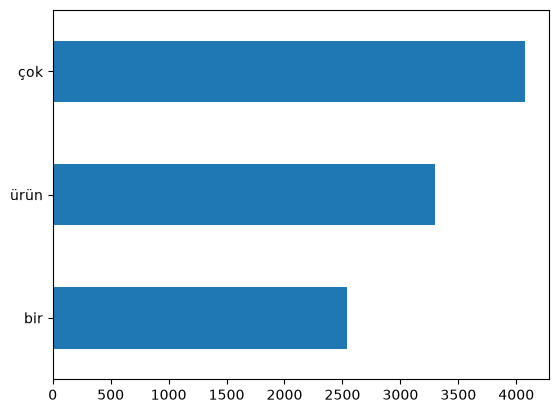

In [57]:
term_ref_tfidf.plot(kind='barh')

In [58]:
from sklearn.model_selection import train_test_split
import pandas as pd

In [59]:
df=pd.read_csv("../data/e-ticaret_urun_yorumlari.csv", sep=",",on_bad_lines="skip")
df

,Metin,Durum
0,evet anlatıldığı gibi,1
1,Daha öncede almıştım bu cihazdan ense ve sakal...,1
2,Ürün gayet başarılı sakal kesmede başlık sayıs...,1
3,Daha öncede aynısını almıştım çok güzel ve kal...,1
4,Erkek kuaförüyüm ense ve sıfır sakal traşı içi...,1
...,...,...
15165,ışık seviyesi rezalet,0
15166,Hic begenmedim. Aydinlatma hic yok ve her kapa...,0
15167,2 gün sonra hoparlörü bozuldu kullanışsız,0
15168,aşırı boğuk bir sesi ve rengi var kumanda heme...,0


In [60]:
df.Durum=df.Durum.fillna('')

In [61]:
print(df.Durum.value_counts())

Durum
0    6978
1    6799
2    1393
Name: count, dtype: int64


In [68]:
y=df.Durum
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,precision_score,recall_score,f1_score

In [73]:
df = df.dropna(subset=['Metin', 'Durum'])

X = df['Metin']
y = df['Durum']
# train/test split
X_train, X_test, y_train, y_test = train_test_split(tfidf_matrix, y, test_size=0.2, random_state=42)

# model
model_nb = MultinomialNB(fit_prior=False)
model_nb.fit(X_train, y_train)

# predict
y_pred_nb = model_nb.predict(X_test)

# evaluate
print(classification_report(y_test, y_pred_nb))
print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb, average='weighted', zero_division=0))
print("Recall:", recall_score(y_test, y_pred_nb, average='weighted', zero_division=0))
print("F1:", f1_score(y_test, y_pred_nb, average='weighted', zero_division=0))

              precision    recall  f1-score   support

           0       0.47      0.65      0.55      1370
           1       0.51      0.28      0.36      1384
           2       0.10      0.12      0.11       280

    accuracy                           0.44      3034
   macro avg       0.36      0.35      0.34      3034
weighted avg       0.45      0.44      0.42      3034

Accuracy: 0.43638760711931446
Precision: 0.45414083565809804
Recall: 0.43638760711931446
F1: 0.4234375528832471
